# Time Series: Linear Trends, Hybrid and Multistep Models

This notebook demonstrates step-by-step techniques for time series forecasting. Each section introduces one technique, applies it to a real dataset, and interprets the result. Including trend, seasonality, lags, leads, holidays and how classical regression and machine-learning models can be combined.


## 1. Setup and Data

Imports, plotting style, helper functions and the main dataset are defined once here and reused in later section.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.signal import periodogram
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_log_error, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputRegressor, RegressorChain
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import LabelEncoder
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.deterministic import CalendarFourier, DeterministicProcess
from xgboost import XGBRegressor

warnings.filterwarnings("ignore", category=FutureWarning)

# Update these path to match where the datasets are stored
data_dir = Path("Data_104")

In [2]:
%config InlineBackend.figure_format = "retina"

plt.style.use("seaborn-v0_8-whitegrid")
plt.rc("figure", autolayout=True, figsize=(11, 4.5))
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=16,
    titlepad=10,
)

# Shared line style: light-grey line with dark markers for observed data
PLOT_PARAMS = dict(
    color="0.75",
    style=".-",
    markeredgecolor="0.25",
    markerfacecolor="0.25",
    legend=False,
)

### Functions

| Function | Purpose |
|----------|---------|
| `make_lags`, `make_leads` | Shifted copies of a series, used as lag and lead features |
| `make_multistep_target` | Builds one target column per forecast step |
| `plot_periodogram` | Variance by frequency, to identify seasonal periods |
| `seasonal_plot` | Overlays seasonal cycles (e.g. one line per week) |
| `lagplot`, `plot_lags` | Scatter plots of a series against its lags and leads, with correlation |
| `plot_multistep` | Draws every multistep forecast path on one axis |

In [3]:
def make_lags(ts, lags, lead_time=1, name="y"):
    """Lagged copies of a series or DataFrame (shifts of lead_time .. lead_time + lags - 1)."""
    return pd.concat(
        {f"{name}_lag_{i}": ts.shift(i) for i in range(lead_time, lags + lead_time)},
        axis=1,
    )


def make_leads(ts, leads, name="y"):
    """Leading copies of a series (future values), e.g. a known promotion schedule."""
    return pd.concat(
        {f"{name}_lead_{i}": ts.shift(-i) for i in reversed(range(1, leads + 1))},
        axis=1,
    )


def make_multistep_target(ts, steps):
    """One target column per forecast step: y_step_1 is t, y_step_2 is t+1, ..."""
    return pd.concat({f"y_step_{i + 1}": ts.shift(-i) for i in range(steps)}, axis=1)


def plot_periodogram(ts, detrend="linear", ax=None):
    """Periodogram of a daily series, with x-axis in cycles per year."""
    frequencies, spectrum = periodogram(
        ts, fs=365, detrend=detrend, window="boxcar", scaling="spectrum"
    )
    if ax is None:
        _, ax = plt.subplots()
    ax.step(frequencies, spectrum, color="purple")
    ax.set_xscale("log")
    ax.set_xticks([1, 2, 4, 6, 12, 26, 52, 104])
    ax.set_xticklabels(
        [
            "Annual (1)",
            "Semiannual (2)",
            "Quarterly (4)",
            "Bimonthly (6)",
            "Monthly (12)",
            "Biweekly (26)",
            "Weekly (52)",
            "Semiweekly (104)",
        ],
        rotation=30,
    )
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax.set_ylabel("Variance")
    ax.set_title("Periodogram")
    return ax


def seasonal_plot(X, y, period, freq, ax=None):
    """One line per `period` (e.g. week) showing the pattern across `freq` (e.g. day of week)."""
    if ax is None:
        _, ax = plt.subplots()
    palette = sns.color_palette("husl", n_colors=X[period].nunique())
    ax = sns.lineplot(
        x=freq, y=y, hue=period, data=X, errorbar=None, ax=ax, palette=palette, legend=False
    )
    ax.set_title(f"Seasonal Plot ({period}/{freq})")
    for line, name in zip(ax.lines, sorted(X[period].unique())):
        ax.annotate(
            name,
            xy=(1, line.get_ydata()[-1]),
            xytext=(6, 0),
            color=line.get_color(),
            xycoords=ax.get_yaxis_transform(),
            textcoords="offset points",
            size=14,
            va="center",
        )
    return ax


def lagplot(x, y=None, shift=1, ax=None, **kwargs):
    """Scatter of y against x shifted by `shift` (negative = lead), with LOWESS fit and correlation."""
    from matplotlib.offsetbox import AnchoredText

    x_ = x.shift(shift)
    y_ = x if y is None else y
    corr = y_.corr(x_)
    if ax is None:
        _, ax = plt.subplots()
    ax = sns.regplot(
        x=x_,
        y=y_,
        scatter_kws=dict(alpha=0.75, s=3),
        line_kws=dict(color="C3"),
        lowess=True,
        ax=ax,
        **kwargs,
    )
    at = AnchoredText(f"{corr:.2f}", prop=dict(size="large"), frameon=True, loc="upper left")
    at.patch.set_boxstyle("square, pad=0.0")
    ax.add_artist(at)
    return ax


def plot_lags(x, y=None, lags=6, leads=0, nrows=1):
    """Grid of lag plots. With leads > 0 the grid also shows lag 0 and the requested leads."""
    shifts = list(range(-leads, lags + 1)) if leads else list(range(1, lags + 1))
    ncols = int(np.ceil(len(shifts) / nrows))
    fig, axs = plt.subplots(
        nrows, ncols, sharex=True, sharey=True, squeeze=False,
        figsize=(ncols * 2, nrows * 2 + 0.5),
    )
    for ax, shift in zip(axs.flat, shifts):
        lagplot(x, y, shift=shift, ax=ax)
        ax.set_title(f"Lead {-shift}" if shift < 0 else f"Lag {shift}", fontsize=14)
        ax.set(xlabel="", ylabel="")
    for ax in axs.flat[len(shifts):]:
        ax.axis("off")
    plt.setp(axs[-1, :], xlabel=x.name)
    plt.setp(axs[:, 0], ylabel=(x if y is None else y).name)
    fig.tight_layout(w_pad=0.1, h_pad=0.1)
    return fig


def plot_multistep(y, every=1, ax=None, palette_kwargs=None):
    """Plot every `every`-th multistep forecast path (rows of y) on a shared axis."""
    palette_kwargs_ = dict(palette="husl", n_colors=16, desat=None)
    if palette_kwargs is not None:
        palette_kwargs_.update(palette_kwargs)
    palette = sns.color_palette(**palette_kwargs_)
    if ax is None:
        _, ax = plt.subplots()
    ax.set_prop_cycle(plt.cycler("color", palette))
    for date, preds in y[::every].iterrows():
        preds.index = pd.period_range(start=date, periods=len(preds))
        preds.plot(ax=ax)
    return ax

### Store sales data

The store-sales dataset is used in most sections, so it is loaded once. Dates become a daily `Period` index, and the data is indexed by `(store, family, date)`. Two aggregates are derived from it:

- `average_sales`: daily sales averaged across all stores and product families (full history).
- `family_sales`: 2017 daily sales and promotion counts, averaged across stores, one column per product family.

In [4]:
store_sales = pd.read_csv(
    data_dir / "train.csv",
    usecols=["store_nbr", "family", "date", "sales", "onpromotion"],
    dtype={
        "store_nbr": "category",
        "family": "category",
        "sales": "float32",
        "onpromotion": "uint32",
    },
    parse_dates=["date"],
)
store_sales["date"] = store_sales["date"].dt.to_period("D")
store_sales = store_sales.set_index(["store_nbr", "family", "date"]).sort_index()

# Chain-wide average daily sales (all years)
average_sales = store_sales.groupby("date")["sales"].mean()

# 2017 sales and promotions per product family (averaged across stores)
family_sales = (
    store_sales
    .groupby(["family", "date"], observed=True)
    .mean()
    .unstack("family")
    .loc["2017"]
)

# National and regional holiday calendar
holidays_events = (
    pd.read_csv(
        data_dir / "holidays_events.csv",
        dtype={
            "type": "category",
            "locale": "category",
            "locale_name": "category",
            "description": "category",
            "transferred": "bool",
        },
        parse_dates=["date"],
    )
    .set_index("date")
    .to_period("D")
)

## 2. Linear Regression with Time-Series Features

A time series can be turned into a standard regression problem with two kinds of features:

- **Time-step feature** (`time = 0, 1, 2, ...)`: $$ \mathbf{target = a (t) + b} $$ models the **trend**.
  
- **Lag feature** (yesterday's value): `target = a * lag_1 + b` models **serial dependence**, i.e. how much the next value depends on the current one.

### 2.1 A minimal example: bookstore sales

Thirty consecutive days of hardcover sales make the mechanics easy to see.

In [5]:
book_sales = pd.read_csv(
    data_dir / "book_sales.csv",
    index_col="Date",
    parse_dates=["Date"],
).drop("Paperback", axis=1)

book_sales.head()

,Hardcover
Date,
2000-04-01,139
2000-04-02,128
2000-04-03,172
2000-04-04,139
2000-04-05,191


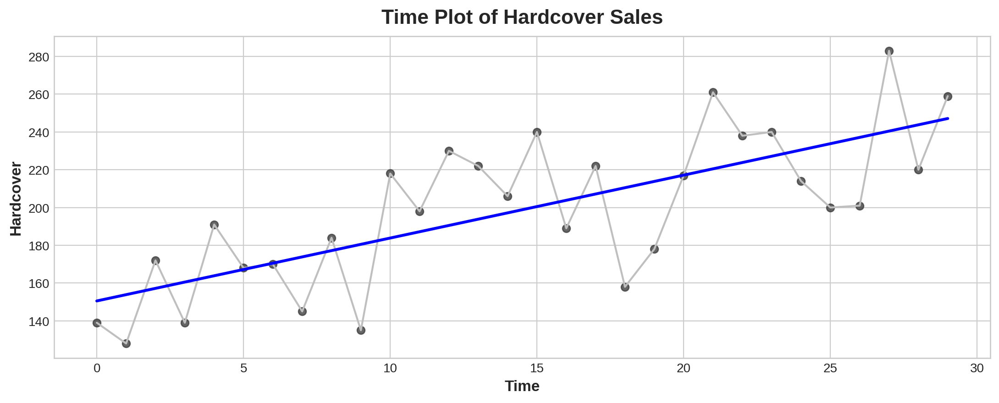

In [6]:
book_sales["Time"] = np.arange(len(book_sales))

fig, ax = plt.subplots()
ax.plot("Time", "Hardcover", data=book_sales, color="0.75")
sns.regplot(x="Time", y="Hardcover", color="b", data=book_sales, ci=None, scatter_kws=dict(color="0.25"), ax=ax)
ax.set_title("Time Plot of Hardcover Sales");

The fitted line is the trend component: despite the day-to-day noise, hardcover sales climb by roughly three copies per day.

In [7]:
book_sales["Lag_1"] = book_sales["Hardcover"].shift(1)

book_sales[["Hardcover", "Lag_1"]].head()

,Hardcover,Lag_1
Date,,
2000-04-01,139,NaN
2000-04-02,128,139.0
2000-04-03,172,128.0
2000-04-04,139,172.0
2000-04-05,191,139.0


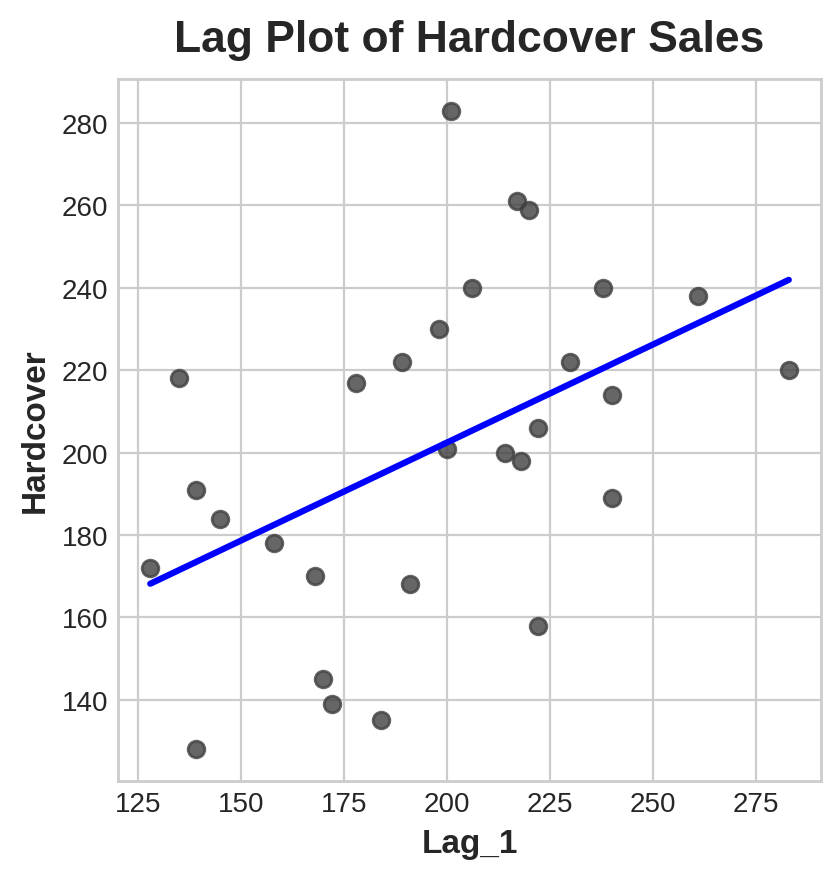

In [8]:
fig, ax = plt.subplots()
sns.regplot(x="Lag_1", y="Hardcover", color="b", data=book_sales, ci=None, scatter_kws=dict(color="0.25"), ax=ax)
ax.set_aspect("equal")
ax.set_title("Lag Plot of Hardcover Sales");

The positive slope shows that a high-sales day tends to be followed by another high-sales day. This **serial dependence** is the information a lag feature can exploit.

### 2.2 Average daily store sales

The same two features applied to chain-wide average daily sales (about 4.6 years of daily data).

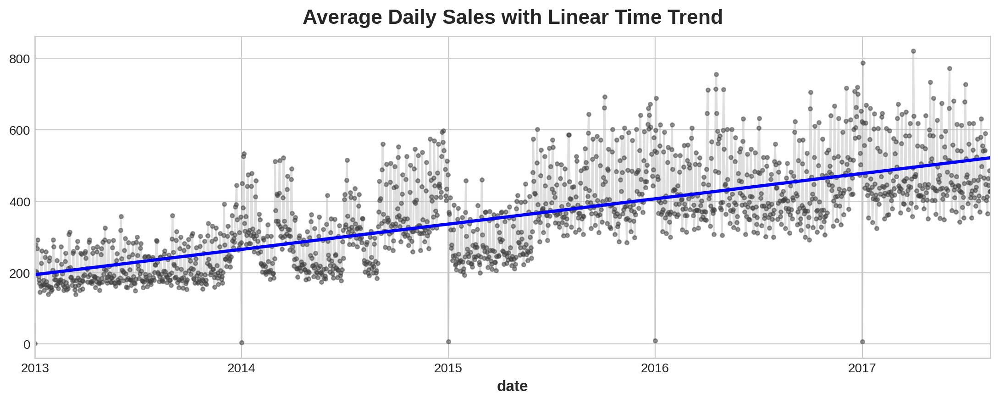

In [9]:
df = average_sales.to_frame()
df["time"] = np.arange(len(df))

X, y = df[["time"]], df["sales"]
model = LinearRegression().fit(X, y)
y_pred = pd.Series(model.predict(X), index=X.index)

ax = y.plot(**PLOT_PARAMS, alpha=0.5)
y_pred.plot(ax=ax, linewidth=2.5, color="b")
ax.set_title("Average Daily Sales with Linear Time Trend");

The linear trend captures long-run growth but none of the weekly cycle, which is why the points scatter widely around the line. The isolated zeros are 1 January of each year, when stores are closed. Both effects are handled explicitly in Section 4.

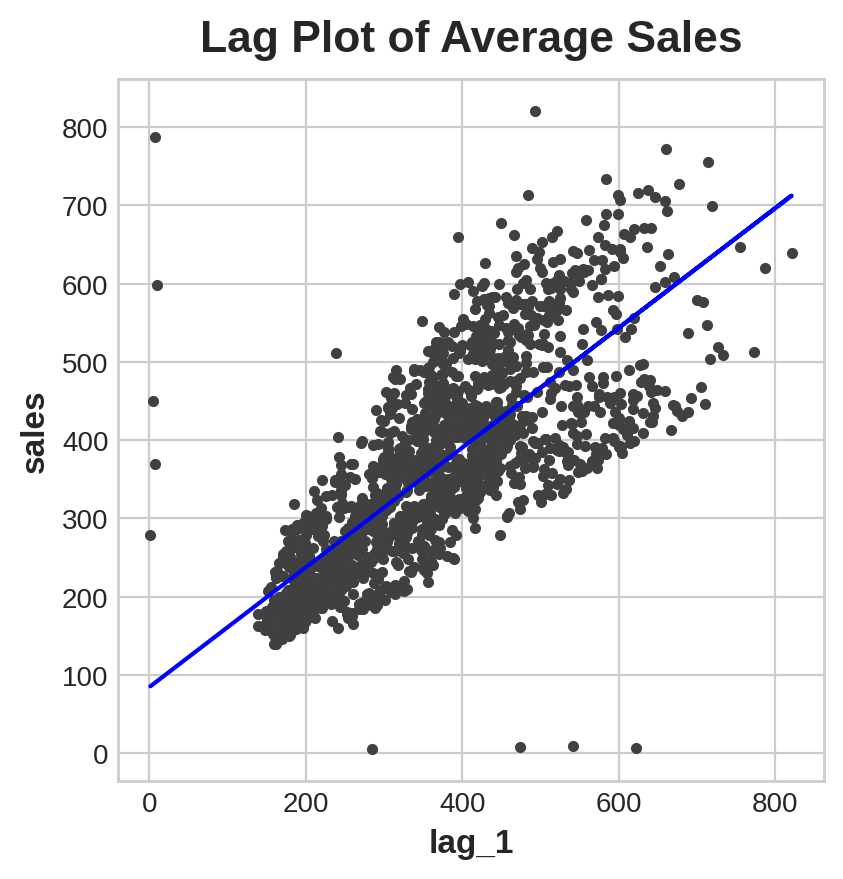

In [10]:
lag_df = average_sales.to_frame()
lag_df["lag_1"] = lag_df["sales"].shift(1)
lag_df = lag_df.dropna()

X, y = lag_df[["lag_1"]], lag_df["sales"]
model = LinearRegression().fit(X, y)
y_pred = pd.Series(model.predict(X), index=X.index)

fig, ax = plt.subplots()
ax.plot(X["lag_1"], y, ".", color="0.25")
ax.plot(X["lag_1"], y_pred, color="b")
ax.set(aspect="equal", xlabel="lag_1", ylabel="sales", title="Lag Plot of Average Sales");

Consecutive days are strongly related. The points lying on the axes come from the 1 January closures and the day after them.

## 3. Trend

The **trend** is the slow, persistent change in the mean of a series. It can be *estimated* with a moving average or *modelled* (and forecast) with a regression on time.

### 3.1 Estimating trend with a moving average

A centred rolling mean over one full seasonal cycle averages the seasonality away. For daily data that means a 365-day window.

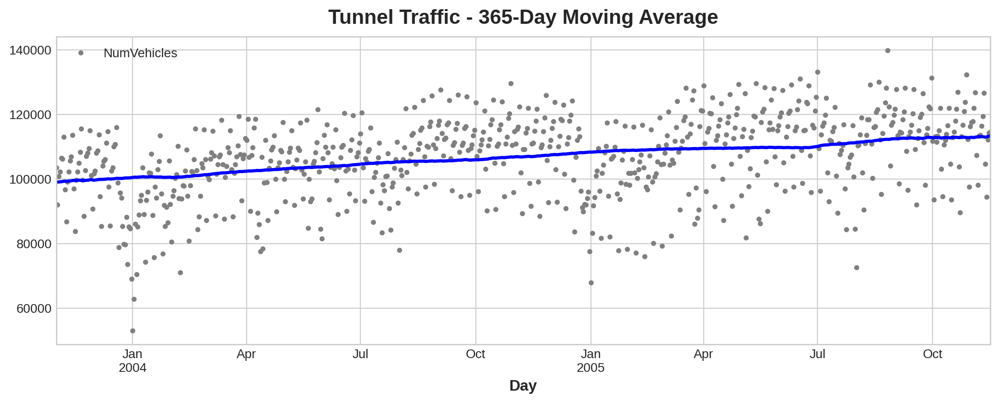

In [11]:
tunnel = (
    pd.read_csv(data_dir / "tunnel.csv", parse_dates=["Day"])
    .set_index("Day")
    .to_period()
)

moving_average = tunnel.rolling(window=365, center=True, min_periods=183).mean()

ax = tunnel.plot(style=".", color="0.5")
moving_average.plot(ax=ax, linewidth=2.5, color="b", title="Tunnel Traffic - 365-Day Moving Average", legend=False);

Tunnel traffic grows gradually, from roughly 100,000 to 113,000 vehicles per day over the two years shown.

### 3.2 Modelling and forecasting a linear trend

`DeterministicProcess` from `statsmodels` generates time-dependent features (constant, trend, polynomial and seasonal terms) for both the training dates and future dates, so training and forecast features are always built consistently.

In [12]:
dp = DeterministicProcess(
    index=tunnel.index,  # dates from the training data
    constant=True,       # intercept column
    order=1,             # linear trend
    drop=True,           # drop terms if necessary to avoid collinearity
)
X = dp.in_sample()

X.head()

,const,trend
Day,,
2003-11-01,1.0,1.0
2003-11-02,1.0,2.0
2003-11-03,1.0,3.0
2003-11-04,1.0,4.0
2003-11-05,1.0,5.0


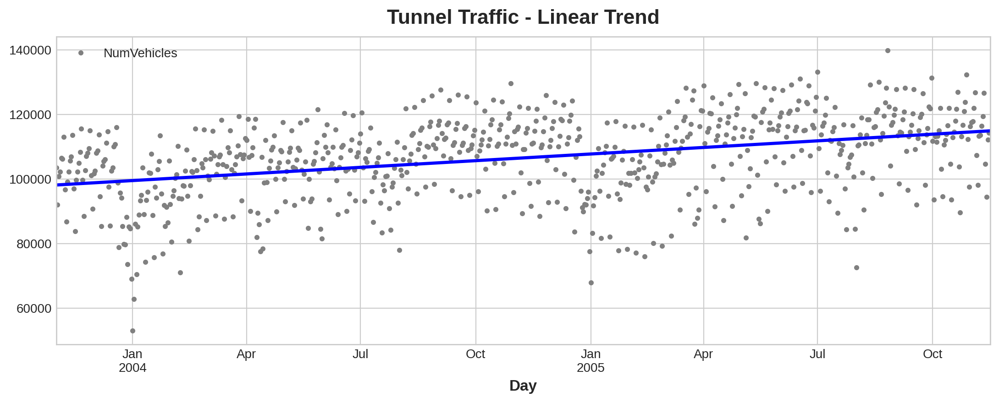

In [13]:
y = tunnel["NumVehicles"]

# `const` already supplies the intercept, so LinearRegression must not add another
model = LinearRegression(fit_intercept=False).fit(X, y)
y_pred = pd.Series(model.predict(X), index=X.index)

ax = tunnel.plot(style=".", color="0.5", title="Tunnel Traffic - Linear Trend")
y_pred.plot(ax=ax, linewidth=2.5, color="b", label="Trend");

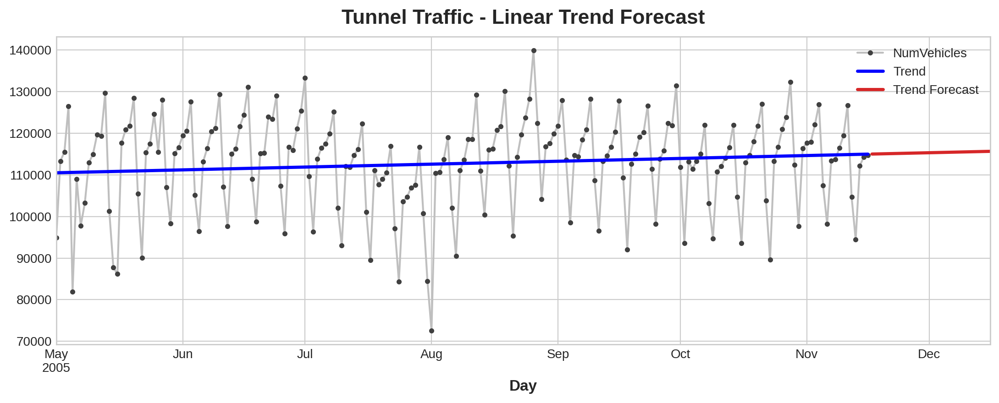

In [14]:
X_fore = dp.out_of_sample(steps=30)
y_fore = pd.Series(model.predict(X_fore), index=X_fore.index)

ax = tunnel["2005-05":].plot(title="Tunnel Traffic - Linear Trend Forecast", **PLOT_PARAMS)
y_pred["2005-05":].plot(ax=ax, linewidth=2.5, color="b", label="Trend")
y_fore.plot(ax=ax, linewidth=2.5, label="Trend Forecast", color="C3")
ax.legend();

The trend forecast continues the fitted line, but it ignores the pronounced weekly cycle in the data. That is addressed in Section 4.

### 3.3 Trend in other series

Monthly US food and beverage sales (12-month window) and average daily store sales (365-day window).

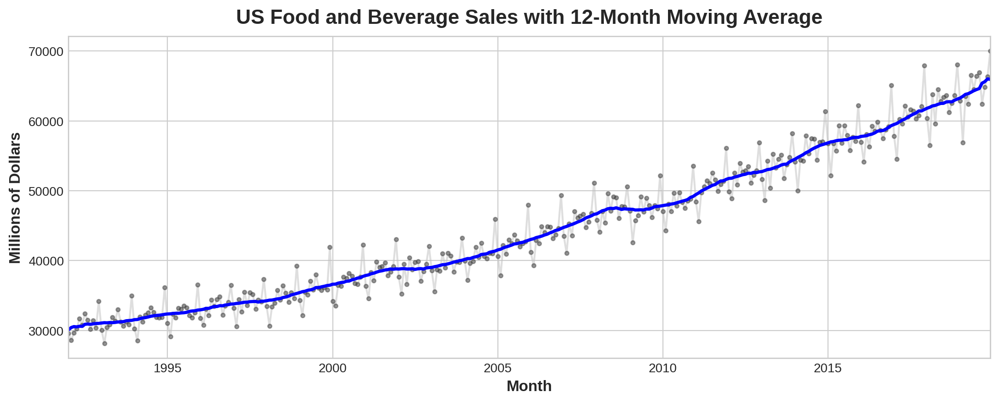

In [15]:
retail_sales = pd.read_csv(
    data_dir / "us-retail-sales.csv",
    parse_dates=["Month"],
    index_col="Month",
).to_period("D")
food_sales = retail_sales["FoodAndBeverage"]

trend = food_sales.rolling(window=12, center=True, min_periods=6).mean()

ax = food_sales.plot(**PLOT_PARAMS, alpha=0.5)
trend.plot(ax=ax, linewidth=2.5, color="b")
ax.set(title="US Food and Beverage Sales with 12-Month Moving Average", ylabel="Millions of Dollars");

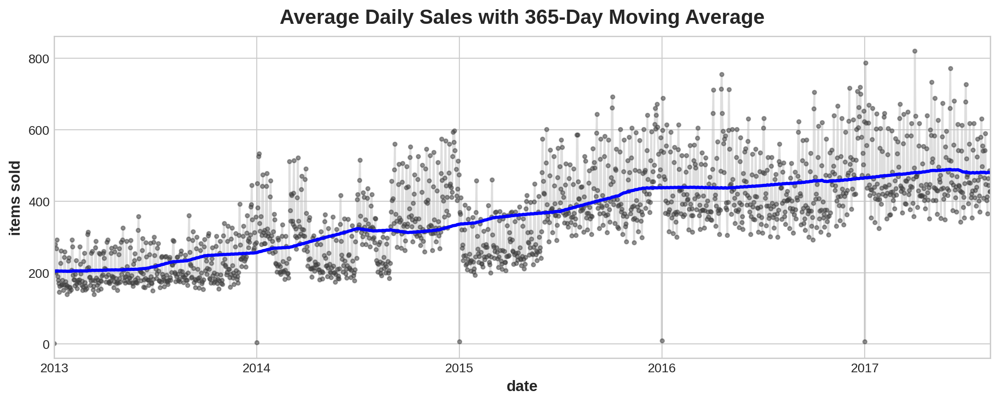

In [16]:
trend = average_sales.rolling(window=365, center=True, min_periods=183).mean()

ax = average_sales.plot(**PLOT_PARAMS, alpha=0.5)
trend.plot(ax=ax, linewidth=2.5, color="b")
ax.set(title="Average Daily Sales with 365-Day Moving Average", ylabel="items sold");

US food and beverage sales grow close to linearly. Store sales grow quickly until about 2016 and then flatten, so a straight line is a poor description of the trend.

### 3.4 Polynomial trends and the risk of extrapolation

Adding polynomial terms lets the trend bend. A cubic trend is a reasonable compromise; an order-11 polynomial fits the history more tightly but extrapolates badly. Both are fitted below with the same helper and forecast 90 days ahead.

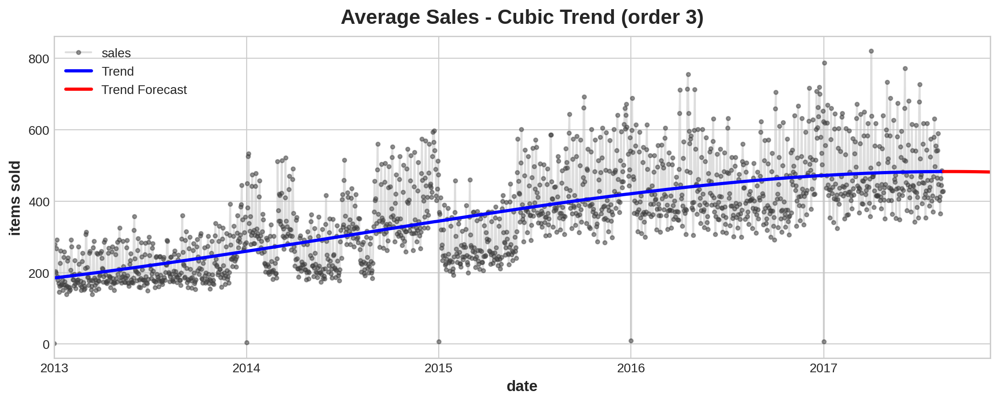

In [17]:
def fit_polynomial_trend(y, order, steps=90):
    """Fit a polynomial trend of the given order and forecast `steps` days ahead."""
    dp = DeterministicProcess(index=y.index, order=order)
    X, X_fore = dp.in_sample(), dp.out_of_sample(steps=steps)
    model = LinearRegression().fit(X, y)
    y_pred = pd.Series(model.predict(X), index=X.index)
    y_fore = pd.Series(model.predict(X_fore), index=X_fore.index)
    return y_pred, y_fore


def plot_trend_forecast(y, y_pred, y_fore, title):
    ax = y.plot(**PLOT_PARAMS, alpha=0.5, title=title, ylabel="items sold")
    y_pred.plot(ax=ax, linewidth=2.5, label="Trend", color="b")
    y_fore.plot(ax=ax, linewidth=2.5, label="Trend Forecast", color="r")
    ax.legend()
    return ax


y = average_sales.copy()

y_pred, y_fore = fit_polynomial_trend(y, order=3)
plot_trend_forecast(y, y_pred, y_fore, "Average Sales - Cubic Trend (order 3)");

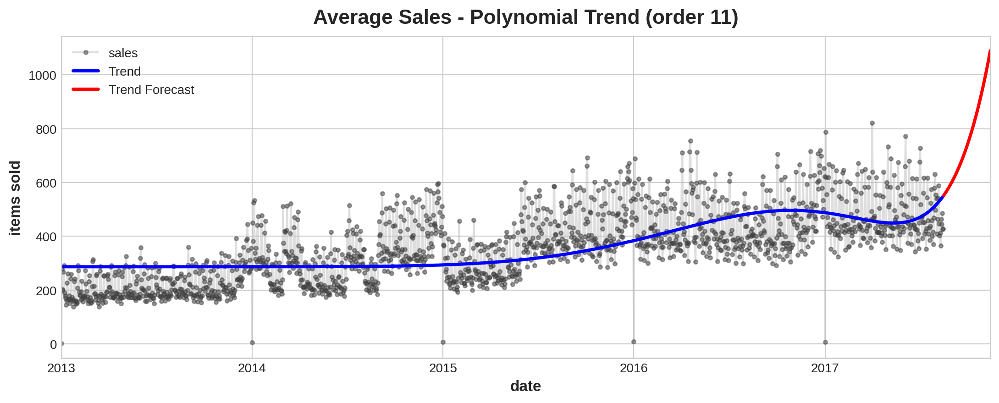

In [18]:
y_pred, y_fore = fit_polynomial_trend(y, order=11)
plot_trend_forecast(y, y_pred, y_fore, "Average Sales - Polynomial Trend (order 11)");

The cubic trend gives a stable, plausible forecast that levels off near the most recent values. The order-11 trend follows the historical wiggles but then shoots above 1,000 items per day, more than double the recent level. **High-order polynomials extrapolate poorly**, so low orders are preferable for forecasting trend.

## 4. Seasonality

**Seasonality** is a regular, periodic change in the mean of a series. Two feature types are used:

- **Indicator features** (one-hot per position in the cycle) suit short periods such as the days of a week.
- **Fourier features** (sine/cosine pairs) represent long periods such as a year with only a few columns.

A **periodogram** shows how much variance each frequency contributes. This guides which seasonal periods to model and how many Fourier pairs to use.

### 4.1 Tunnel traffic: weekly indicators and annual Fourier terms

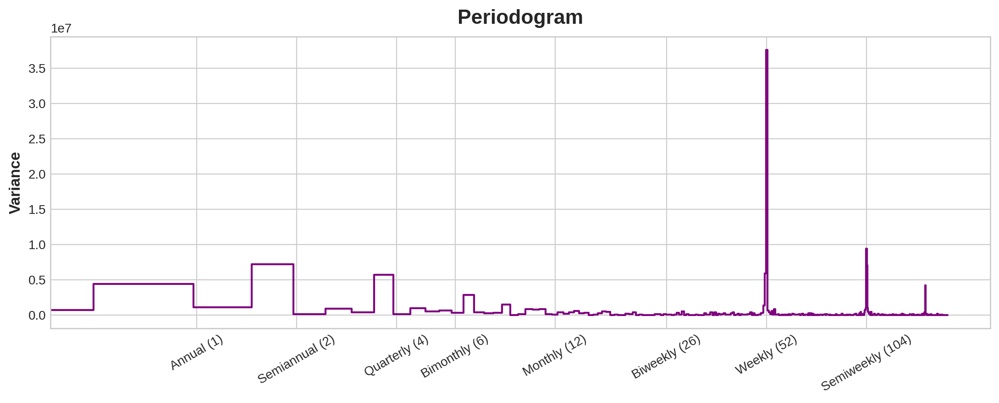

In [19]:
plot_periodogram(tunnel["NumVehicles"]);

The weekly frequency dominates, with a secondary spike at semiweekly (the first harmonic of the weekly pattern) and smaller low-frequency components around annual to quarterly. The model therefore uses weekly indicators plus annual Fourier terms.

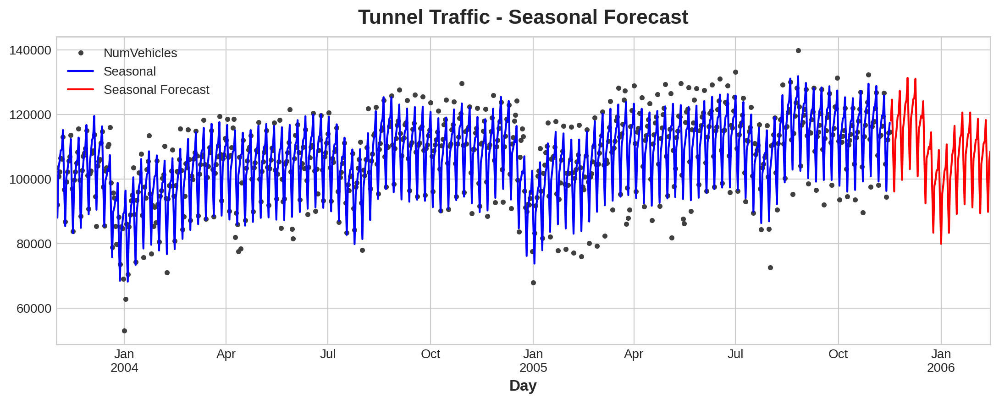

In [20]:
fourier = CalendarFourier(freq="A", order=10)  # 10 sin/cos pairs for annual seasonality

dp = DeterministicProcess(
    index=tunnel.index,
    constant=True,
    order=1,                     # linear trend
    seasonal=True,               # weekly seasonality via indicators
    additional_terms=[fourier],  # annual seasonality via Fourier terms
    drop=True,
)
X = dp.in_sample()
y = tunnel["NumVehicles"]

model = LinearRegression(fit_intercept=False).fit(X, y)
y_pred = pd.Series(model.predict(X), index=y.index)

X_fore = dp.out_of_sample(steps=90)
y_fore = pd.Series(model.predict(X_fore), index=X_fore.index)

ax = y.plot(color="0.25", style=".", title="Tunnel Traffic - Seasonal Forecast")
y_pred.plot(ax=ax, color="b", label="Seasonal")
y_fore.plot(ax=ax, label="Seasonal Forecast", color="r")
ax.legend();

The seasonal model reproduces the weekly rhythm and the slower annual swing, and the 90-day forecast continues both patterns, which the trend-only model in Section 3 could not.

### 4.2 Store sales: weekly and monthly seasonality

This analysis uses 2017 only (1 January to 15 August).

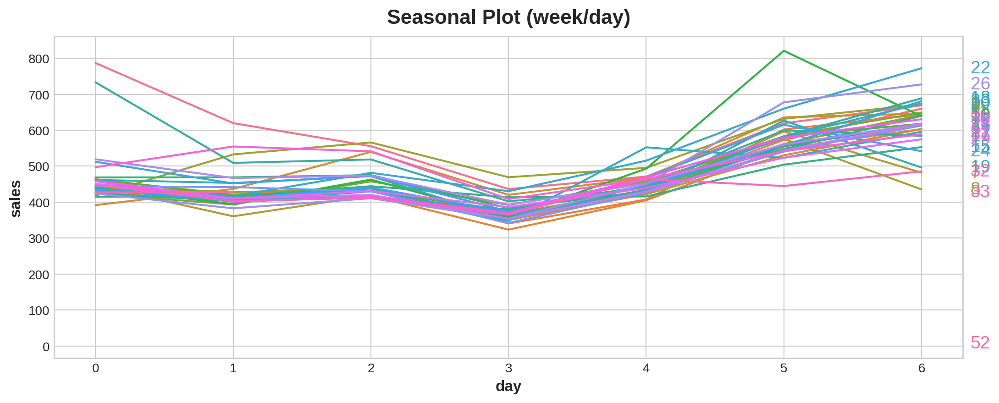

In [21]:
average_sales_2017 = average_sales.loc["2017"]

X = average_sales_2017.to_frame()
X["week"] = X.index.week
X["day"] = X.index.dayofweek  # 0 = Monday

seasonal_plot(X, y="sales", period="week", freq="day");

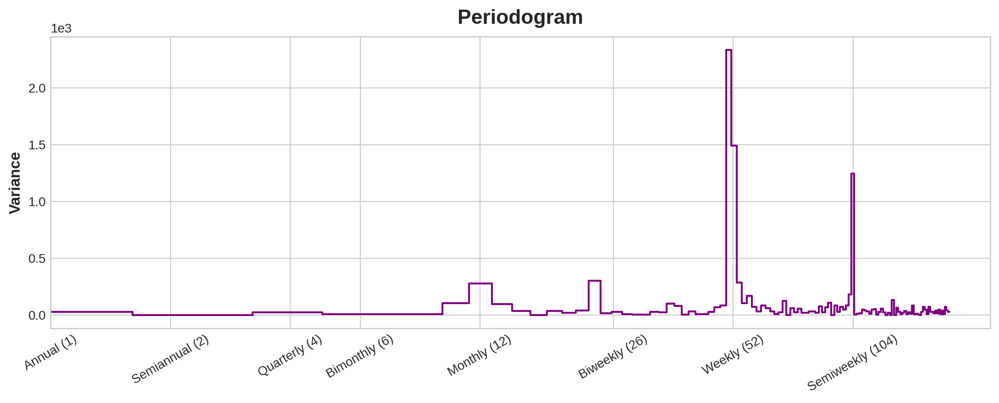

In [22]:
plot_periodogram(average_sales_2017);

Sales are lowest around Thursday (day 3) and peak on the weekend (days 5 and 6), and the pattern repeats almost identically every week. The periodogram agrees: weekly and semiweekly spikes dominate, with smaller monthly and biweekly components. The model below combines weekly indicators with monthly Fourier terms (order 4).

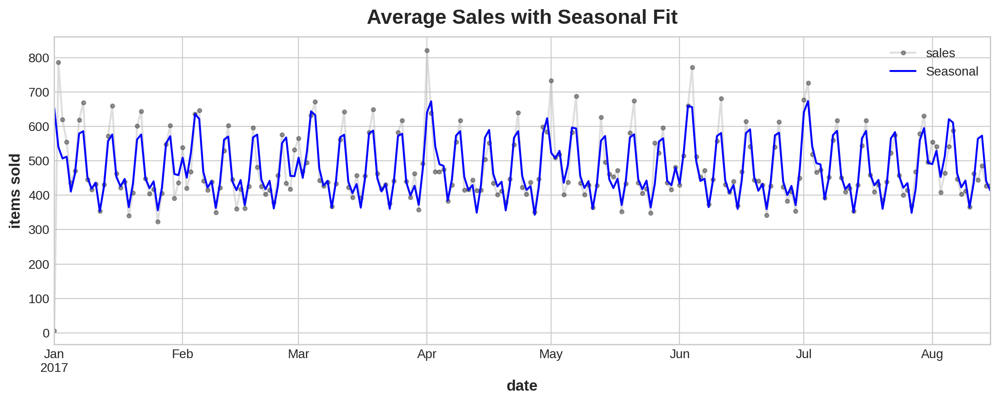

In [23]:
y = average_sales_2017.copy()

fourier = CalendarFourier(freq="M", order=4)  # monthly seasonality
dp = DeterministicProcess(
    index=y.index,
    constant=True,
    order=1,
    seasonal=True,               # weekly indicators
    additional_terms=[fourier],
    drop=True,
)
X = dp.in_sample()

model = LinearRegression().fit(X, y)
y_pred = pd.Series(model.predict(X), index=X.index, name="Fitted")

ax = y.plot(**PLOT_PARAMS, alpha=0.5, title="Average Sales with Seasonal Fit", ylabel="items sold")
y_pred.plot(ax=ax, color="b", label="Seasonal")
ax.legend();

A good check on a seasonal model is to **subtract the fit and re-run the periodogram**. If the seasonal structure was captured, its spikes should disappear.

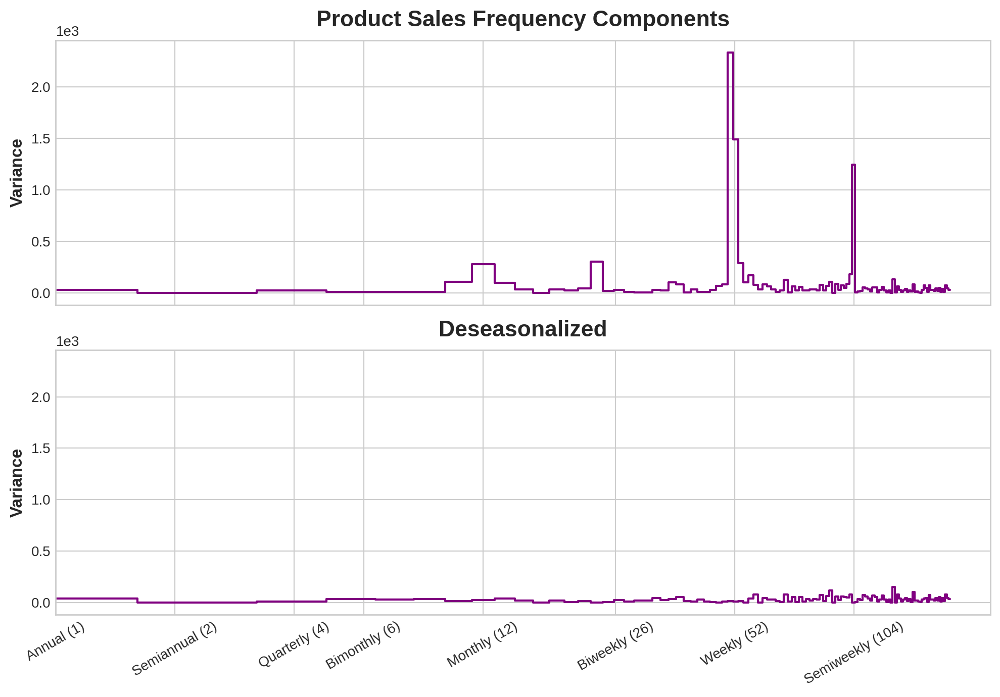

In [24]:
y_deseason = y - y_pred

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, sharey=True, figsize=(10, 7))
plot_periodogram(y, ax=ax1).set_title("Product Sales Frequency Components")
plot_periodogram(y_deseason, ax=ax2).set_title("Deseasonalized");

The weekly and semiweekly spikes are gone after deseasonalising, so the model has absorbed the periodic structure. What remains is mostly noise plus one-off events such as holidays.

### 4.3 Holiday effects

Holidays are events rather than periodic patterns, so they are modelled with one-hot indicators. The red points below mark national and regional holidays on the deseasonalised series.

In [25]:
# National and regional holidays within the training window
holidays = (
    holidays_events
    .query("locale in ['National', 'Regional']")
    .loc["2017":"2017-08-15", ["description"]]
    .assign(description=lambda x: x.description.cat.remove_unused_categories())
)

display(holidays)

,description
date,
2017-01-01,Primer dia del ano
2017-01-02,Traslado Primer dia del ano
2017-02-27,Carnaval
2017-02-28,Carnaval
2017-04-01,Provincializacion de Cotopaxi
2017-04-14,Viernes Santo
2017-05-01,Dia del Trabajo
2017-05-13,Dia de la Madre-1
2017-05-14,Dia de la Madre


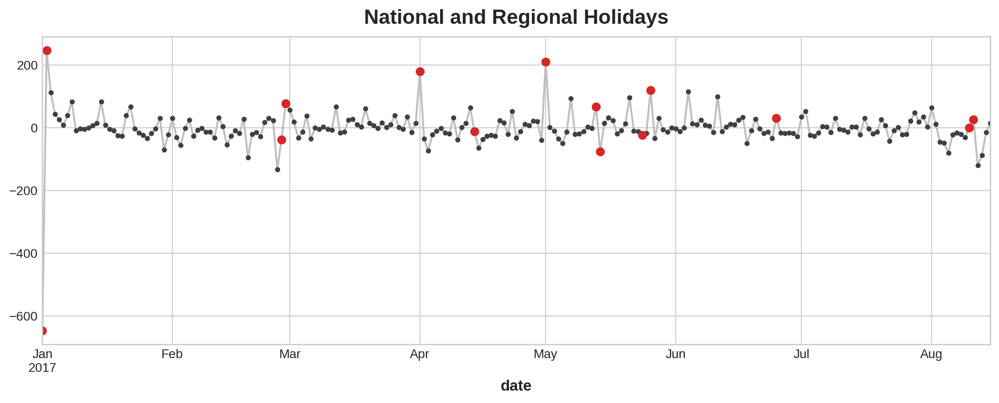

In [26]:
ax = y_deseason.plot(**PLOT_PARAMS)
ax.plot(holidays.index, y_deseason[holidays.index], "o", color="C3")
ax.set_title("National and Regional Holidays");

Several of the largest residual swings, including 1 January, early April and 1 May, coincide with holidays.

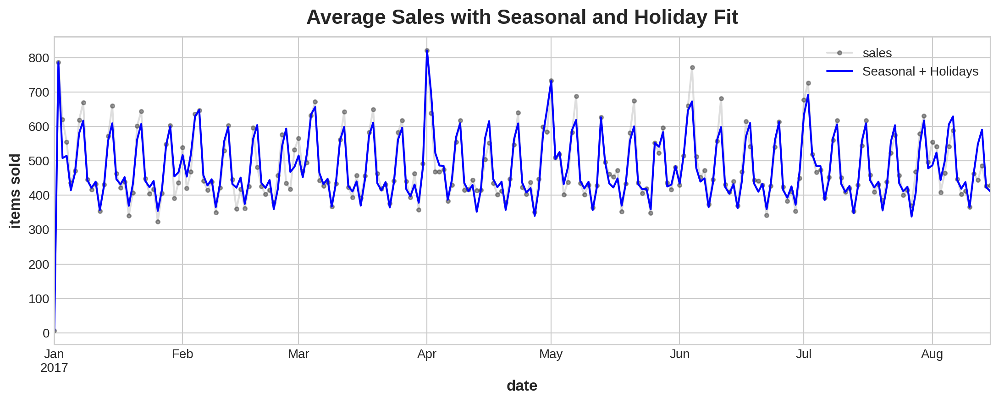

In [27]:
X_holidays = pd.get_dummies(holidays)
X_with_holidays = X.join(X_holidays).fillna(0.0)

model = LinearRegression().fit(X_with_holidays, y)
y_pred = pd.Series(model.predict(X_with_holidays), index=X_with_holidays.index, name="Fitted")

ax = y.plot(**PLOT_PARAMS, alpha=0.5, title="Average Sales with Seasonal and Holiday Fit", ylabel="items sold")
y_pred.plot(ax=ax, color="b", label="Seasonal + Holidays")
ax.legend();

The holiday indicators let the model reproduce the holiday-related spikes. **Caveat:** each holiday occurs only once in this eight-month window, so each indicator fits its single observation exactly. This is an in-sample illustration. Learning reliable holiday effects requires several years of history.

### 4.4 Scaling up: one model for every store and product family

The same feature set (trend, weekly indicators, monthly Fourier terms) plus a New Year's Day indicator is fitted to all store-family series at once. `LinearRegression` supports multi-output targets, so a single call fits roughly 1,800 separate regressions.

In [28]:
y = store_sales[["sales"]].unstack(["store_nbr", "family"]).loc["2017"]

fourier = CalendarFourier(freq="M", order=4)
dp = DeterministicProcess(
    index=y.index,
    constant=True,
    order=1,
    seasonal=True,
    additional_terms=[fourier],
    drop=True,
)
X = dp.in_sample()
X["NewYear"] = X.index.dayofyear == 1

model = LinearRegression(fit_intercept=False).fit(X, y)
y_pred = pd.DataFrame(model.predict(X), index=X.index, columns=y.columns)

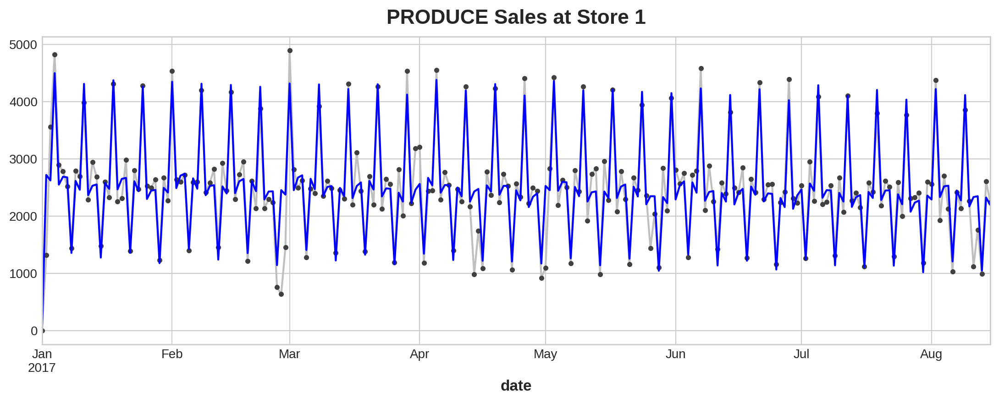

In [29]:
STORE_NBR = "1"      # 1 - 54
FAMILY = "PRODUCE"   # any product family

ax = y.loc(axis=1)["sales", STORE_NBR, FAMILY].plot(**PLOT_PARAMS)
y_pred.loc(axis=1)["sales", STORE_NBR, FAMILY].plot(ax=ax, color="b")
ax.set_title(f"{FAMILY} Sales at Store {STORE_NBR}");

For this store-family pair the model reproduces the strong weekly cycle. Remaining errors are irregular dips (for instance in early March) that no calendar feature explains, which motivates the lag-based features in Section 5.

## 5. Lags and Leads as Features

Trend and seasonality are *deterministic* patterns that can be computed from the calendar alone. Many series also have **cyclic** behaviour, where today's value depends on recent values, as in epidemics or promotions. Lagged values capture this. The **partial autocorrelation function (PACF)** shows how many lags carry independent information.

### 5.1 Flu trends: weekly doctor visits

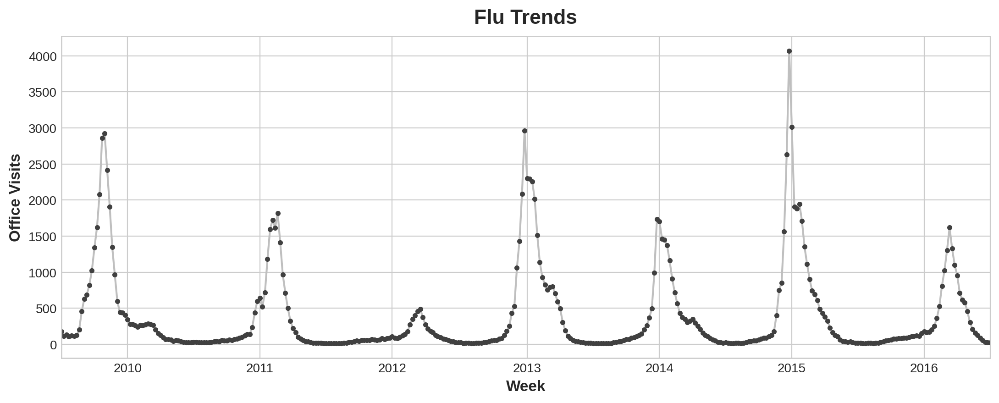

In [30]:
flu_trends = pd.read_csv(data_dir / "flu-trends.csv")
flu_trends = flu_trends.set_index(pd.PeriodIndex(flu_trends.Week, freq="W")).drop(columns="Week")

ax = flu_trends.FluVisits.plot(title="Flu Trends", **PLOT_PARAMS)
ax.set(ylabel="Office Visits");

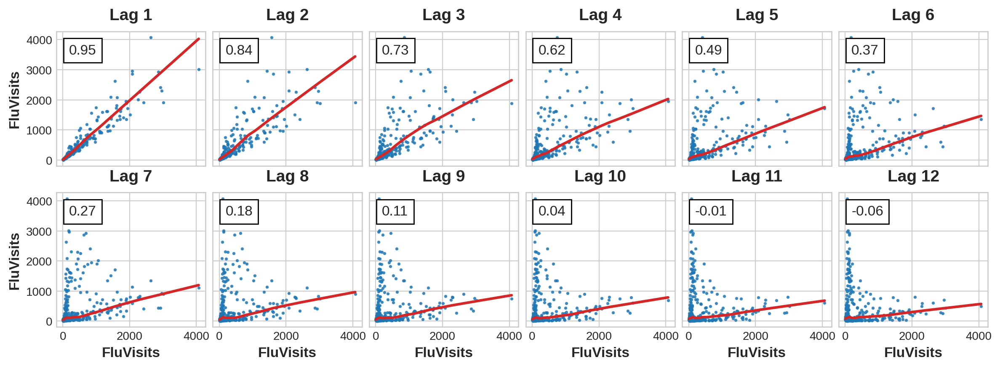

In [31]:
plot_lags(flu_trends.FluVisits, lags=12, nrows=2);

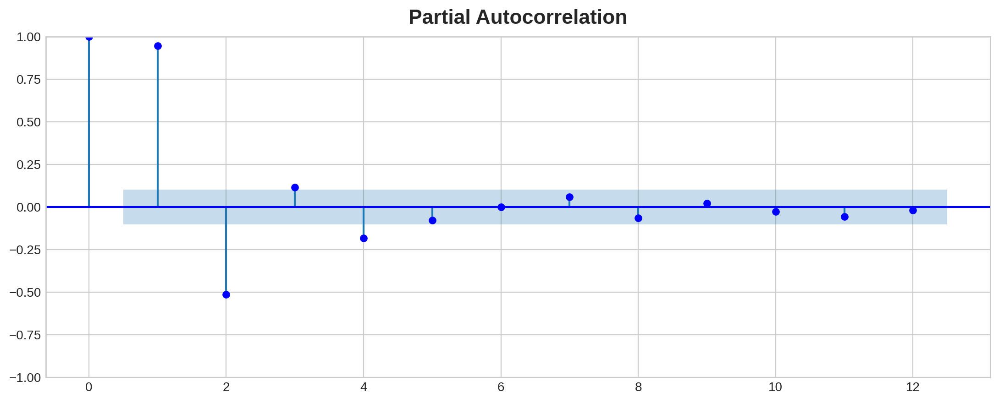

In [32]:
plot_pacf(flu_trends.FluVisits, lags=12, color="b");

The correlation with the previous week is 0.95 and decays steadily, reaching roughly zero by lag 10. The PACF shows that lags 1, 2 and 4 stand out once shorter lags are accounted for. Four lags are therefore used as features.

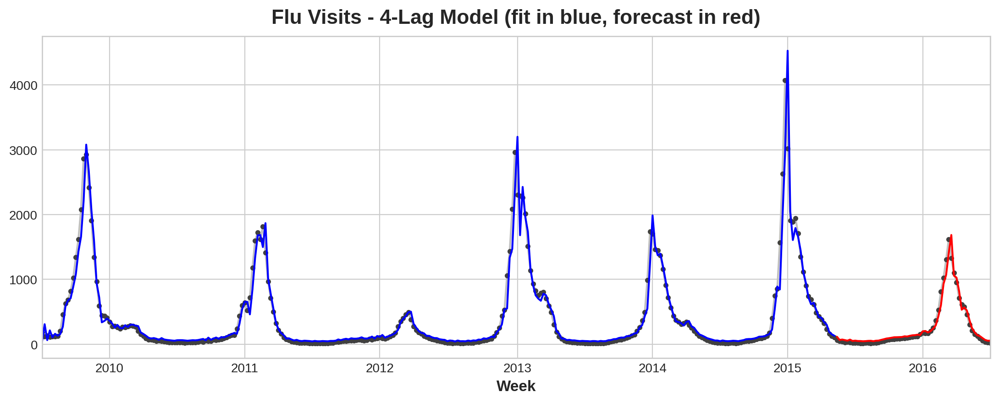

In [33]:
y = flu_trends.FluVisits
X = make_lags(y, lags=4).fillna(0.0)

# Time-ordered split: hold out the last 60 weeks
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=60, shuffle=False)

model = LinearRegression().fit(X_train, y_train)
y_pred = pd.Series(model.predict(X_train), index=y_train.index)
y_fore = pd.Series(model.predict(X_test), index=y_test.index)

ax = y_train.plot(**PLOT_PARAMS)
y_test.plot(ax=ax, **PLOT_PARAMS)
y_pred.plot(ax=ax, color="b")
y_fore.plot(ax=ax, color="r")
ax.set(title="Flu Visits - 4-Lag Model (fit in blue, forecast in red)");

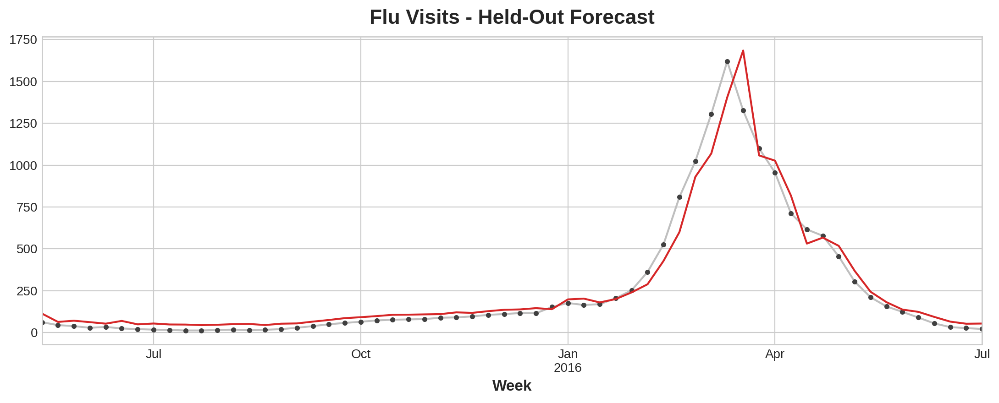

In [34]:
ax = y_test.plot(**PLOT_PARAMS)
y_fore.plot(ax=ax, color="C3")
ax.set(title="Flu Visits - Held-Out Forecast");

The lag model fits the training seasons closely and follows the held-out season, but it is a **one-step-behind forecast**. At turning points the forecast simply echoes the previous week's value, so the predicted peak arrives about a week after the actual one.

### Adding search-term features

Google search volumes for flu-related queries may carry early information about an outbreak.

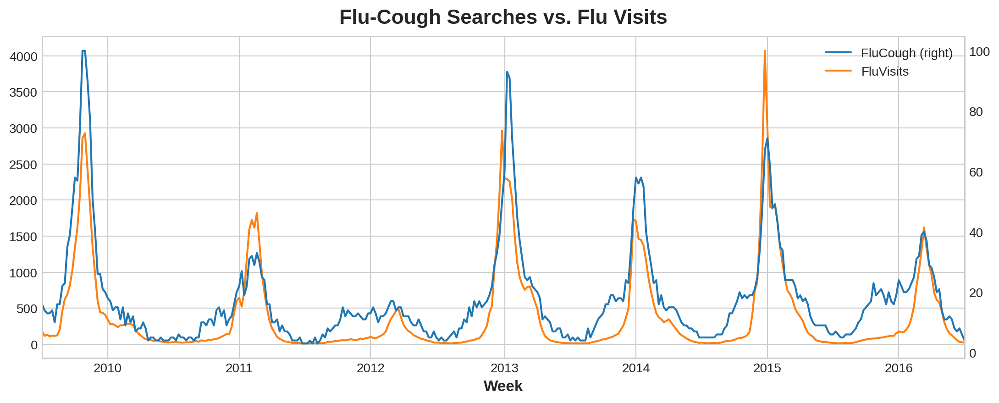

In [35]:
ax = flu_trends.plot(
    y=["FluCough", "FluVisits"], 
    secondary_y="FluCough",
    title="Flu-Cough Searches vs. Flu Visits",
)

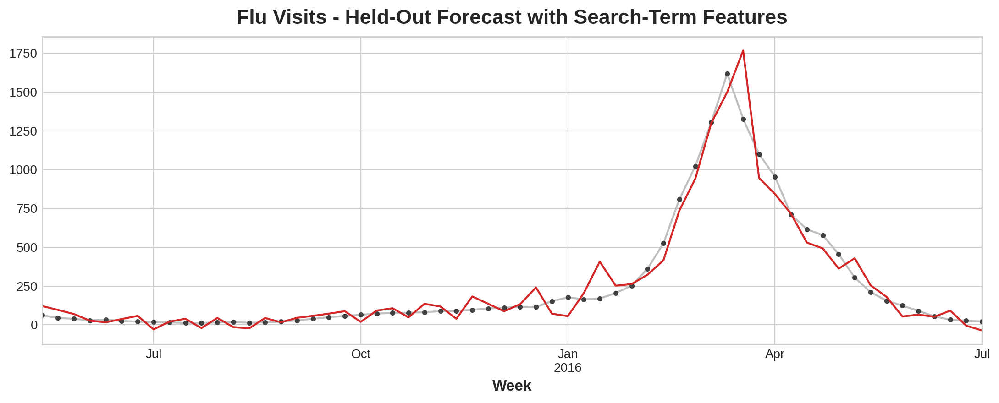

In [36]:
search_terms = [
    "FluContagious", "FluCough", "FluFever", "InfluenzaA",
    "TreatFlu", "IHaveTheFlu", "OverTheCounterFlu", "HowLongFlu",
]

# Lagged search volumes (3 lags each) plus lags of the target itself
X0 = make_lags(flu_trends[search_terms], lags=3)
X0.columns = [" ".join(col).strip() for col in X0.columns.values]
X1 = make_lags(flu_trends["FluVisits"], lags=4)
X = pd.concat([X0, X1], axis=1).fillna(0.0)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=60, shuffle=False)

model = LinearRegression().fit(X_train, y_train)
y_fore = pd.Series(model.predict(X_test), index=y_test.index)

ax = y_test.plot(**PLOT_PARAMS)
y_fore.plot(ax=ax, color="C3")
ax.set(title="Flu Visits - Held-Out Forecast with Search-Term Features");

Search-term features are lagged, so only information available at forecast time is used and there is no leakage. The added features give the model more signal about the outbreak, but the forecast becomes noisier outside the flu season and occasionally dips below zero. That is a typical trade-off for an unregularised linear model with many correlated features. Regularisation or a quantitative comparison (Section 8) would be the next step.

### 5.2 School and office supplies: lagged sales and promotions

For a product family with strong, irregular seasonality, the workflow is: remove the calendar-driven component, inspect what remains, then add lag and lead features.

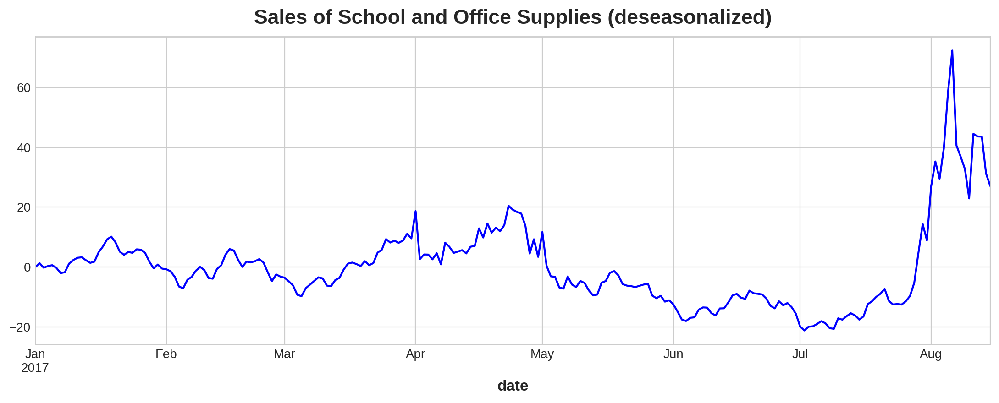

In [37]:
supply_sales = family_sales.loc(axis=1)[:, "SCHOOL AND OFFICE SUPPLIES"]
y = supply_sales.loc[:, "sales"].squeeze()
onpromotion = supply_sales.loc[:, "onpromotion"].squeeze().rename("onpromotion")

# Remove trend, weekly and monthly seasonality, and the New Year effect
fourier = CalendarFourier(freq="M", order=4)
dp = DeterministicProcess(
    index=y.index,
    constant=True,
    order=1,
    seasonal=True,
    additional_terms=[fourier],
    drop=True,
)
X_time = dp.in_sample()
X_time["NewYearsDay"] = X_time.index.dayofyear == 1

model = LinearRegression(fit_intercept=False).fit(X_time, y)
y_deseason = y - model.predict(X_time)
y_deseason.name = "sales_deseasoned"

ax = y_deseason.plot(color="b")
ax.set_title("Sales of School and Office Supplies (deseasonalized)");

The deseasonalised series is smooth and slowly varying, with a hump around April and a sharp surge in August (the back-to-school period). Such persistence suggests strong autocorrelation.

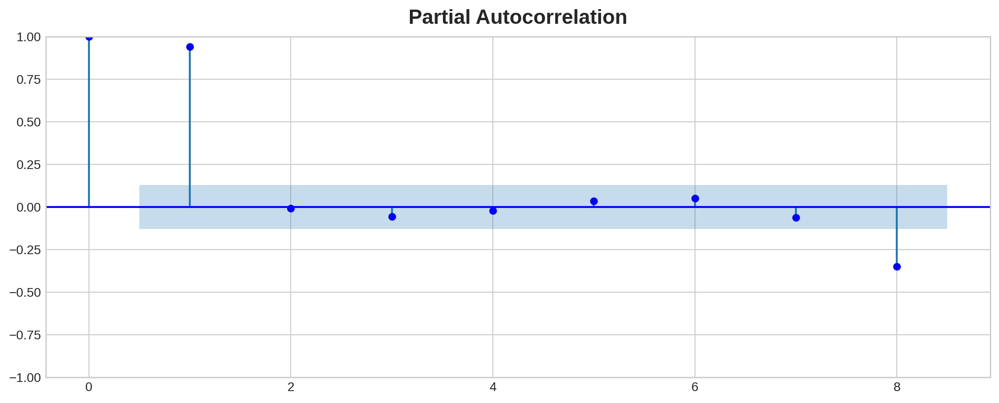

In [38]:
plot_pacf(y_deseason, lags=8,color="b");

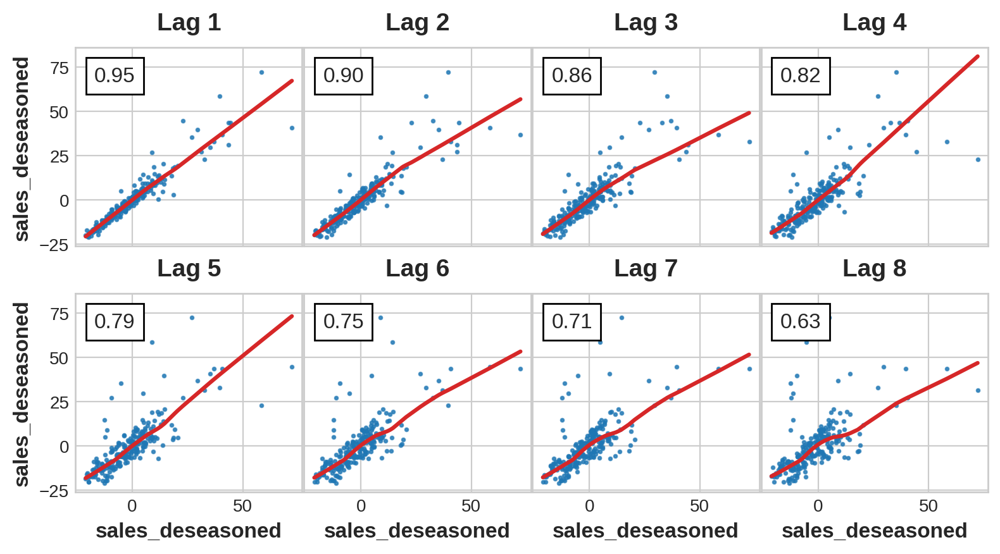

In [39]:
plot_lags(y_deseason, lags=8, nrows=2);

Lag-1 correlation is 0.95 and the PACF is dominated by a single spike at lag 1 (a smaller negative spike appears at lag 8), so one lag of the target is used. Next, the relationship with the number of items on promotion is checked at several lags and leads. A lead is a *future* promotion value, which is legitimate here because promotion schedules are planned in advance (the competition's test file includes them).

*Note: the plot is restricted to days with more than one item on promotion, and lags and leads are counted among those days. This is an approximation of calendar-day lags, adequate for spotting the pattern.*

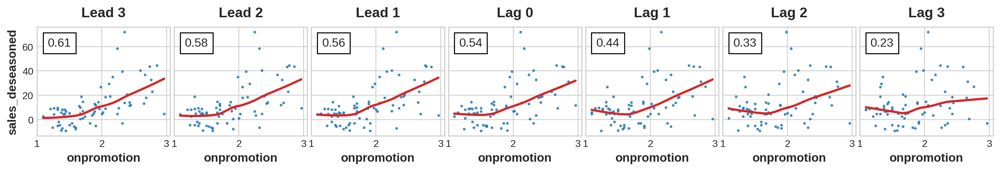

In [40]:
plot_lags(
    x=onpromotion.loc[onpromotion > 1],
    y=y_deseason.loc[onpromotion > 1],
    lags=3, leads=3, nrows=1,
);

Correlation with sales is **stronger for leads than for lags**: 0.61 at lead 3 against 0.23 at lag 3. Upcoming promotions are more informative about current sales than past ones, so both lead and lag features are used.

Training RMSLE: 0.82857
Validation RMSLE: 1.15613


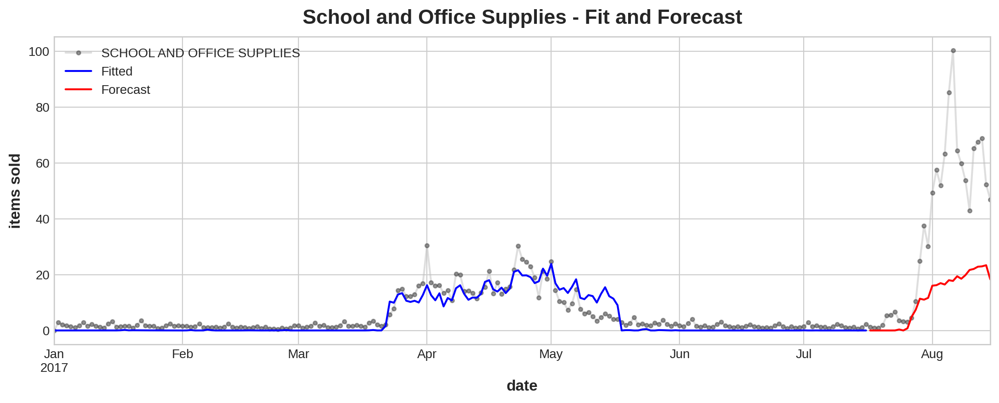

In [41]:
X_lags = make_lags(y_deseason, lags=1)
X_promo = pd.concat(
    [
        make_lags(onpromotion, lags=1, name="onpromotion"),
        onpromotion,
        make_leads(onpromotion, leads=1, name="onpromotion"),
    ],
    axis=1,
)
X = pd.concat([X_lags, X_promo], axis=1).fillna(0)

# Time-ordered split: hold out the last 30 days
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=30, shuffle=False)

model = LinearRegression(fit_intercept=False).fit(X_train, y_train)
y_fit = pd.Series(model.predict(X_train), index=X_train.index).clip(0.0)
y_pred = pd.Series(model.predict(X_valid), index=X_valid.index).clip(0.0)

rmsle_train = mean_squared_log_error(y_train, y_fit) ** 0.5
rmsle_valid = mean_squared_log_error(y_valid, y_pred) ** 0.5
print(f"Training RMSLE: {rmsle_train:.5f}")
print(f"Validation RMSLE: {rmsle_valid:.5f}")

ax = y.plot(**PLOT_PARAMS, alpha=0.5, title="School and Office Supplies - Fit and Forecast", ylabel="items sold")
y_fit.plot(ax=ax, label="Fitted", color="b")
y_pred.plot(ax=ax, label="Forecast", color="r")
ax.legend();

The model fits the spring hump well and detects the *onset* of the August surge, but it **under-predicts the surge's size** (the forecast reaches about 20 items against actual values of 40 to 100). The validation RMSLE (1.17) is above the training RMSLE (0.83), as expected when the held-out window contains an event that is absent from most of the training data. Capturing it would require a longer history that includes previous back-to-school seasons.

## 6. Hybrid Models

Different models have complementary strengths:

- **Linear regression** extrapolates trends, but cannot easily learn complex seasonal interactions.
- **Gradient boosting / tree models** learn complex interactions, but cannot extrapolate a trend beyond the range seen in training.

A **boosted hybrid** combines them. A linear model first fits the trend (and, where useful, seasonality). A second model is then trained on the **residuals** of the first, and the final forecast is the sum of the two.

### 6.1 US retail sales: quadratic trend + XGBoost

Two industries (`BuildingMaterials`, `FoodAndBeverage`) are modelled together. The last four years are held out as a test set.

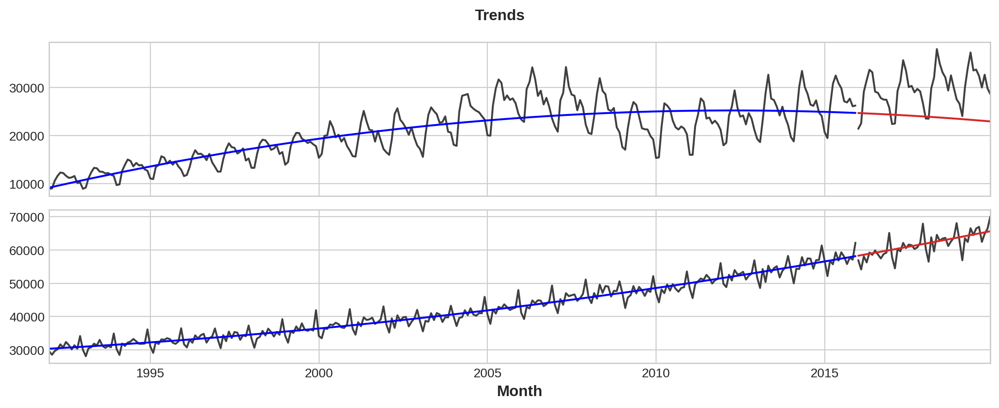

In [42]:
industries = ["BuildingMaterials", "FoodAndBeverage"]
retail = pd.concat({"Sales": retail_sales[industries]}, names=[None, "Industries"], axis=1)

y = retail.copy()

# Stage 1: quadratic trend
dp = DeterministicProcess(index=y.index, constant=True, order=2, drop=True)
X = dp.in_sample()

# Hold out the last 48 months. Splitting the index keeps features and targets aligned.
idx_train, idx_test = train_test_split(y.index, test_size=12 * 4, shuffle=False)
X_train, X_test = X.loc[idx_train, :], X.loc[idx_test, :]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

model = LinearRegression(fit_intercept=False).fit(X_train, y_train)

y_fit = pd.DataFrame(model.predict(X_train), index=y_train.index, columns=y_train.columns)
y_pred = pd.DataFrame(model.predict(X_test), index=y_test.index, columns=y_test.columns)

axs = y_train.plot(color="0.25", subplots=True, sharex=True)
axs = y_test.plot(color="0.25", subplots=True, ax=axs)
axs = y_fit.plot(color="b", subplots=True, ax=axs)
axs = y_pred.plot(color="C3", subplots=True, ax=axs)
for ax in axs:
    ax.legend([])
plt.suptitle("Trends", fontweight="bold");

The quadratic trend works well for `FoodAndBeverage` (bottom) but for `BuildingMaterials` (top) it flattens and then declines in the test window while the real series keeps growing. Seasonality is not modelled at all at this stage.

**Stage 2** reshapes the data into long format (one row per month and industry), adds an industry label and a month-of-year feature, and fits XGBoost to the stage-1 residuals.

In [43]:
# Wide -> long: one row per (month, industry)
X = retail.stack()
y = X.pop("Sales")

# Features for the residual model: industry (label-encoded) and month of year
X = X.reset_index("Industries")
X["Industries"], _ = X["Industries"].factorize()
X["Month"] = X.index.month

X_train, X_test = X.loc[idx_train, :], X.loc[idx_test, :]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

# Stage-1 trend predictions in long format, and the residuals the second model must explain
y_fit = y_fit.stack().squeeze()
y_pred = y_pred.stack().squeeze()
y_resid = y_train - y_fit

# Stage 2: XGBoost on the residuals; final forecast = trend + predicted residual
xgb = XGBRegressor()
xgb.fit(X_train, y_resid)

y_fit_boosted = xgb.predict(X_train) + y_fit
y_pred_boosted = xgb.predict(X_test) + y_pred

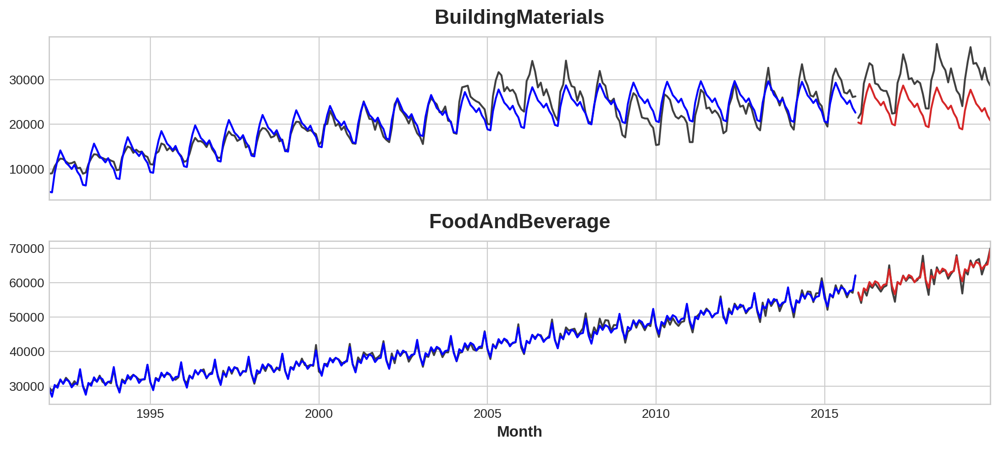

In [44]:
axs = y_train.unstack(["Industries"]).plot(
    color="0.25", figsize=(11, 5), subplots=True, sharex=True,
    title=["BuildingMaterials", "FoodAndBeverage"],
)
axs = y_test.unstack(["Industries"]).plot(color="0.25", subplots=True, ax=axs)
axs = y_fit_boosted.unstack(["Industries"]).plot(color="b", subplots=True, ax=axs)
axs = y_pred_boosted.unstack(["Industries"]).plot(color="C3", subplots=True, ax=axs)
for ax in axs:
    ax.legend([])

The residual model learns the seasonal shape and the hybrid now follows the yearly cycle in both industries. `FoodAndBeverage` is forecast closely. The `BuildingMaterials` forecast keeps the right seasonality but sits **below the actual values**, because XGBoost cannot correct a trend that the linear stage has under-estimated. This illustrates why the quality of the trend stage matters in a boosted hybrid.

### 6.2 A reusable hybrid class for store sales

The two-stage logic is wrapped in a small class that accepts any pair of scikit-learn-compatible models. Stage 1 is fitted per series on time features. Stage 2 is fitted on residuals stacked across all product families, using promotions, product family and day of month as features.

In [45]:
class BoostedHybrid:
    """Two-stage hybrid forecaster.

    model_1 learns each series' trend from X_1 (one column per series in y).
    model_2 learns the stacked residuals from X_2 (one row per date and series).
    """

    def __init__(self, model_1, model_2):
        self.model_1 = model_1
        self.model_2 = model_2
        self.y_columns = None

    def fit(self, X_1, X_2, y):
        self.model_1.fit(X_1, y)
        y_fit = pd.DataFrame(self.model_1.predict(X_1), index=X_1.index, columns=y.columns)
        y_resid = (y - y_fit).stack().squeeze()
        self.model_2.fit(X_2, y_resid)

        self.y_columns = y.columns
        self.y_fit, self.y_resid = y_fit, y_resid
        return self

    def predict(self, X_1, X_2):
        y_pred = pd.DataFrame(
            self.model_1.predict(X_1), index=X_1.index, columns=self.y_columns
        ).stack().squeeze()
        y_pred += self.model_2.predict(X_2)
        return y_pred.unstack()

In [46]:
y = family_sales["sales"]

# Stage-1 features: constant and linear trend
dp = DeterministicProcess(index=y.index, order=1)
X_1 = dp.in_sample()

# Stage-2 features: promotions, label-encoded product family, day of month
X_2 = family_sales.drop("sales", axis=1).stack()
X_2 = X_2.reset_index("family")
X_2["family"] = LabelEncoder().fit_transform(X_2["family"])
X_2["day"] = X_2.index.day

# Time-ordered split at 1 July 2017
y_train, y_valid = y.loc[:"2017-07-01"], y.loc["2017-07-02":]
X1_train, X1_valid = X_1.loc[:"2017-07-01"], X_1.loc["2017-07-02":]
X2_train, X2_valid = X_2.loc[:"2017-07-01"], X_2.loc["2017-07-02":]

Ridge regression handles the trend and k-nearest-neighbours the residuals. Any combination of regressors can be swapped in.

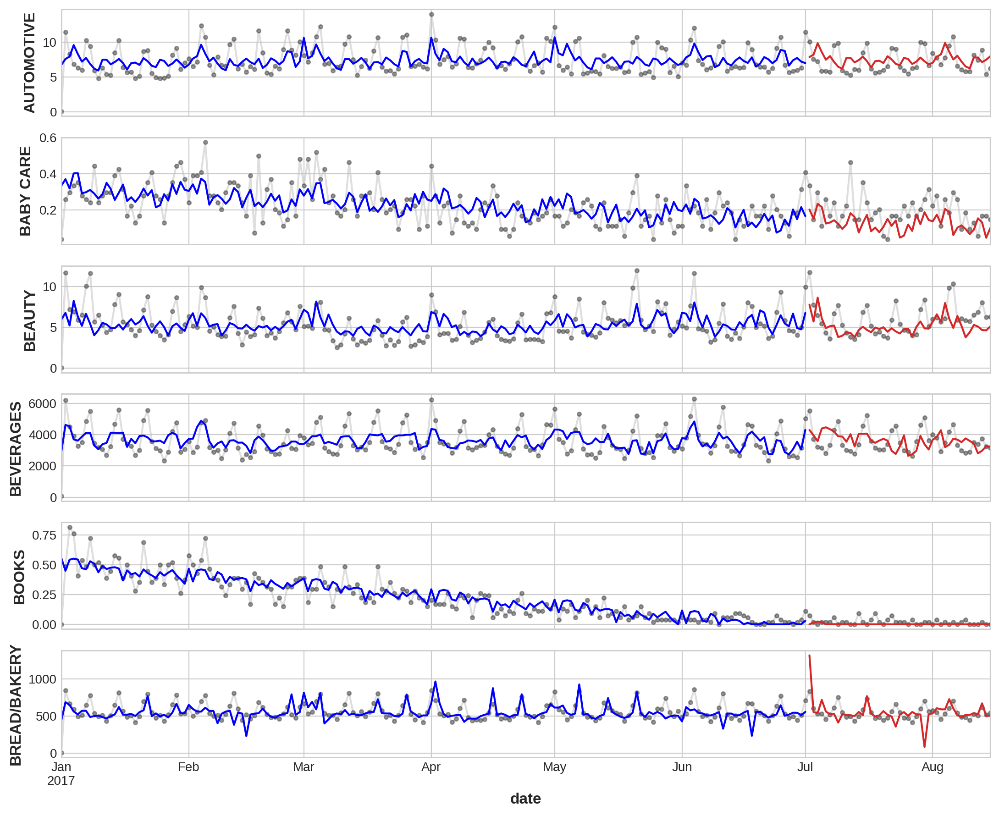

In [47]:
model = BoostedHybrid(model_1=Ridge(), model_2=KNeighborsRegressor())
model.fit(X1_train, X2_train, y_train)

y_fit = model.predict(X1_train, X2_train).clip(0.0)
y_pred = model.predict(X1_valid, X2_valid).clip(0.0)

families = y.columns[0:6]
axs = y.loc(axis=1)[families].plot(
    subplots=True, sharex=True, figsize=(11, 9), **PLOT_PARAMS, alpha=0.5
)
y_fit.loc(axis=1)[families].plot(subplots=True, color="b", ax=axs)
y_pred.loc(axis=1)[families].plot(subplots=True, color="C3", ax=axs)
for ax, family in zip(axs, families):
    ax.legend([])
    ax.set_ylabel(family)

The hybrid fits all six product families with one model and produces sensible forecasts for the held-out period (red), including the steady decline of `BOOKS` to near zero. Some artefacts remain, such as the spike at the start of the validation window for `BREAD/BAKERY`.

## 7. Multistep Forecasting

Forecasting several steps ahead needs a strategy for the multiple targets. Two are used here:

- **Direct (multi-output)**: train one model per horizon step, each predicting `y(t + k)` directly from features available at time `t`. This avoids accumulating errors, but ignores the relationship between steps.
- **Chained (DirRec)**: like direct, but each step's model also receives the predictions of the earlier steps as features.

The layout of features and targets for a 3-step forecast with a 2-step lead time is illustrated below. Targets (pink) are the next three values; features (purple) are lags 2 to 6, because the most recent value is not yet known at forecast time.

In [48]:
N = 20
ts = pd.Series(
    np.arange(N),
    index=pd.period_range(start="2010", freq="A", periods=N, name="Year"),
    dtype=np.float64,
)
X = pd.DataFrame({f"y_lag_{i}": ts.shift(i) for i in range(2, 7)})
y = pd.DataFrame({
    "y_step_3": ts.shift(-2),
    "y_step_2": ts.shift(-1),
    "y_step_1": ts,
})
data = pd.concat({"Targets": y, "Features": X}, axis=1)

(
    data.head(10)
    .style.set_properties(["Targets"], **{"background-color": "LavenderBlush"})
    .set_properties(["Features"], **{"background-color": "Lavender"})
)

### 7.1 Flu visits: 8-week horizon, linear vs. XGBoost

The same lag features forecast the next eight weeks at once. A plain `LinearRegression` handles multiple targets natively, while `MultiOutputRegressor` fits one XGBoost model per step. Both are evaluated on the last 25% of the data.

Train RMSE: 389.12
Test RMSE: 582.33


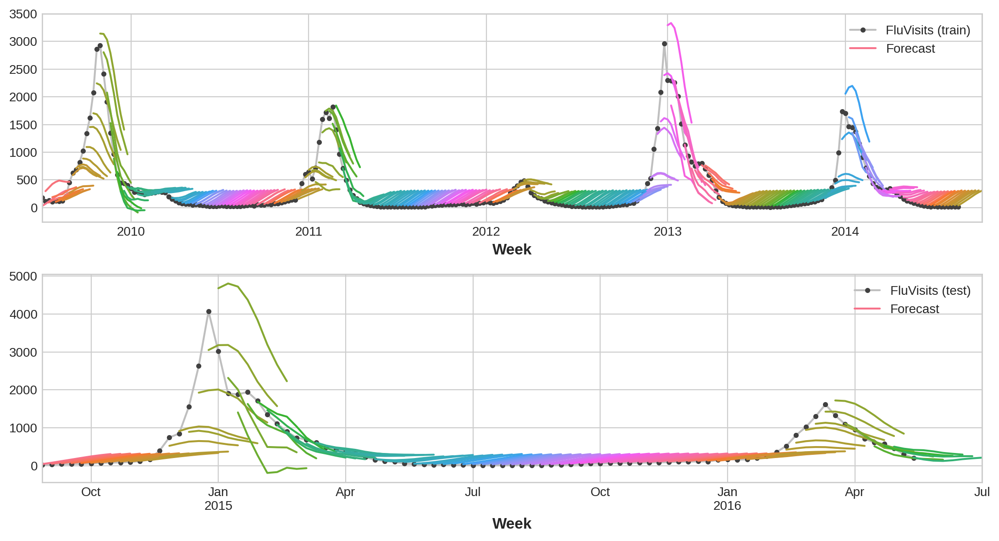

In [49]:
y = flu_trends.FluVisits.copy()
X = make_lags(y, lags=4).fillna(0.0)
y = make_multistep_target(y, steps=8).dropna()
y, X = y.align(X, join="inner", axis=0)

splits = train_test_split(X, y, test_size=0.25, shuffle=False)


def evaluate_multistep(model, splits, series):
    """Fit a multistep model, print train/test RMSE and plot all forecast paths."""
    X_train, X_test, y_train, y_test = splits
    model.fit(X_train, y_train)
    y_fit = pd.DataFrame(model.predict(X_train), index=X_train.index, columns=y_train.columns)
    y_pred = pd.DataFrame(model.predict(X_test), index=X_test.index, columns=y_test.columns)

    print(f"Train RMSE: {root_mean_squared_error(y_train, y_fit):.2f}")
    print(f"Test RMSE: {root_mean_squared_error(y_test, y_pred):.2f}")

    palette = dict(palette="husl", n_colors=64)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6))
    ax1 = series[y_fit.index].plot(**PLOT_PARAMS, ax=ax1)
    ax1 = plot_multistep(y_fit, ax=ax1, palette_kwargs=palette)
    ax1.legend(["FluVisits (train)", "Forecast"])
    ax2 = series[y_pred.index].plot(**PLOT_PARAMS, ax=ax2)
    ax2 = plot_multistep(y_pred, ax=ax2, palette_kwargs=palette)
    ax2.legend(["FluVisits (test)", "Forecast"])


evaluate_multistep(LinearRegression(), splits, flu_trends.FluVisits)

Train RMSE: 1.19
Test RMSE: 494.52


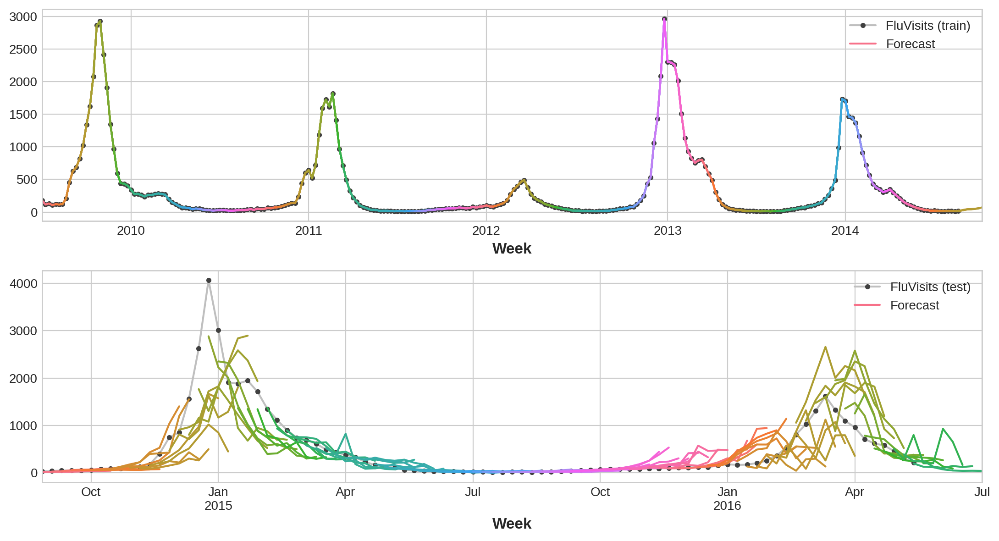

In [50]:
evaluate_multistep(MultiOutputRegressor(XGBRegressor()), splits, flu_trends.FluVisits)

| Model | Train RMSE | Test RMSE |
|-------|-----------:|----------:|
| Linear regression | 540.55 | **697.92** |
| XGBoost (one model per step) | **195.80** | 798.03 |

XGBoost fits the training seasons far more tightly but generalises worse. With only a handful of flu seasons in the data, the tree model **overfits**, and it cannot extrapolate beyond the peak sizes it has seen (the 2014-15 peak of about 4,000 visits in the test period is larger than any peak in the training period). The simpler linear model has the better test error.

### 7.2 Store sales: 16-day horizon with a regressor chain

For the store-sales data, a `RegressorChain` forecasts 16 days ahead using four lags of sales. Each step's XGBoost model receives the earlier steps' predictions as extra features. All product families share one model, with the family label-encoded as a feature.

In [51]:
y = family_sales["sales"]
X = make_lags(y, lags=4).fillna(0.0)
y = make_multistep_target(y, steps=16).dropna()
y, X = y.align(X, join="inner", axis=0)

# Wide -> long: one row per (date, family), with family label-encoded
X = (
    X.stack("family")
    .reset_index("family")
    .assign(family=lambda x: LabelEncoder().fit_transform(x.family))
)
y = y.stack("family")

model = RegressorChain(XGBRegressor())
model.fit(X, y)

y_pred = pd.DataFrame(model.predict(X), index=y.index, columns=y.columns).clip(0.0)

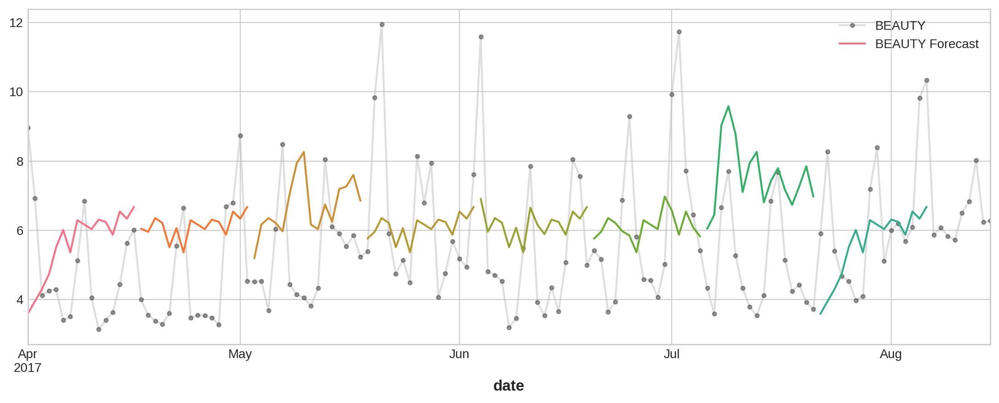

In [52]:
FAMILY = "BEAUTY"
START = "2017-04-01"
EVERY = 16  # draw one 16-day forecast path per horizon

y_pred_ = y_pred.xs(FAMILY, level="family", axis=0).loc[START:]
y_ = family_sales.loc[START:, "sales"].loc[:, FAMILY]

fig, ax = plt.subplots()
y_.plot(**PLOT_PARAMS, ax=ax, alpha=0.5)
plot_multistep(y_pred_, ax=ax, every=EVERY)
ax.legend([FAMILY, FAMILY + " Forecast"]);

Each coloured segment is one 16-day forecast issued at its starting date. The paths follow the level and weekly pattern of the series. *These are in-sample fits that illustrate the chained approach, not a held-out evaluation.*

## 8. Conclusions

### Key findings

- **Calendar features go a long way.** Trend, weekly indicators and Fourier terms explain most of the structure in daily store sales. After deseasonalising, the weekly and semiweekly spikes vanish from the periodogram.
- **Trend extrapolation is fragile.** A cubic trend produced a stable forecast; an order-11 polynomial fitted the history tightly and then forecast more than double the recent level.
- **Autoregressive features work but lag at turning points.** Flu visits have a lag-1 correlation of 0.95, and a 4-lag model tracks them well, but the forecast follows the actual peak by about a week.
- **Leads can be more informative than lags.** Upcoming promotions correlated more strongly with sales (0.61 at lead 3) than past promotions did (0.23 at lag 3).
- **Hybrids combine complementary strengths.** A linear trend plus a residual learner captured both trend and seasonality, but only as well as the trend stage allowed (`BuildingMaterials` was under-forecast).
- **More flexible is not always better.** For 8-week flu forecasts XGBoost reduced training RMSE from 540.6 to 195.8 yet raised test RMSE from 697.9 to 798.0.
